Enter number of learning rates: 5
Enter Learning Rate 1: 0.001
Enter Learning Rate 2: 0.01
Enter Learning Rate 3: 0.1
Enter Learning Rate 4: 1
Enter Learning Rate 5: 1.1

Enter number of epoch values: 4
Enter Epoch Value 1: 1
Enter Epoch Value 2: 5
Enter Epoch Value 3: 10
Enter Epoch Value 4: 20

Training Started...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learning Rate Results
   Learning Rate  Epochs      Loss  Accuracy
0          0.001       5  0.353305    0.8736
1          0.010       5  0.407279    0.8517
2          0.100       5  1.707550    0.2799
3          1.000       5  2.332710    0.1000
4          1.100       5  2.364310    0.1000



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch Results
   Learning Rate  Epochs      Loss  Accuracy
0          0.001       1  0.450051    0.8363
1          0.001       5  0.359111    0.8728
2          0.001      10  0.347960    0.8762
3          0.001      20  0.366214    0.8838

FINAL COMPARISON TABLE
   Learning Rate  Epochs    Loss  Accuracy
0          0.001       5  0.3533    0.8736
1          0.010       5  0.4073    0.8517
2          0.100       5  1.7075    0.2799
3          1.000       5  2.3327    0.1000
4          1.100       5  2.3643    0.1000
5          0.001       1  0.4501    0.8363
6          0.001       5  0.3591    0.8728
7          0.001      10  0.3480    0.8762
8          0.001      20  0.3662    0.8838

Best Configuration

Learning Rate     0.0010
Epochs           20.0000
Loss              0.3662
Accuracy          0.8838
Name: 8, dtype: float64


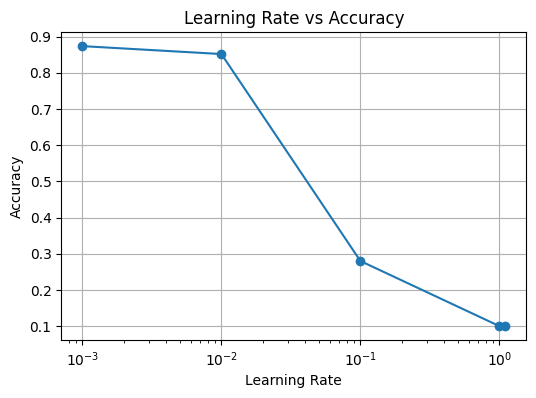

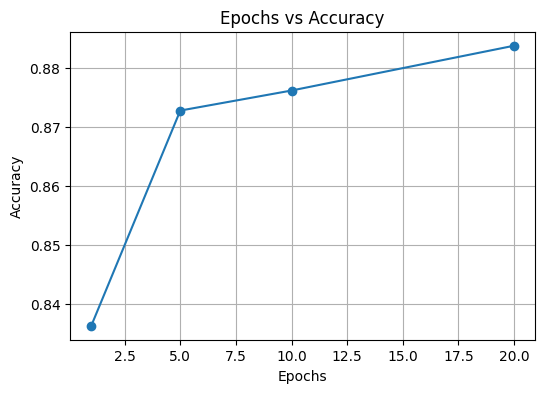

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8032 - loss: 0.5727 - val_accuracy: 0.8458 - val_loss: 0.4413
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8575 - loss: 0.4021 - val_accuracy: 0.8631 - val_loss: 0.3831
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8702 - loss: 0.3589 - val_accuracy: 0.8707 - val_loss: 0.3609
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8791 - loss: 0.3322 - val_accuracy: 0.8703 - val_loss: 0.3557
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8867 - loss: 0.3097 - val_accuracy: 0.8767 - val_loss: 0.3438
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8907 - loss: 0.2960 - val_accuracy: 0.8758 - val_loss: 0.3413
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8948 - loss: 0.2846 - val_accuracy: 0.8818 - val_loss: 0.3321
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8961 - loss: 0.2768 - val_accuracy: 0.

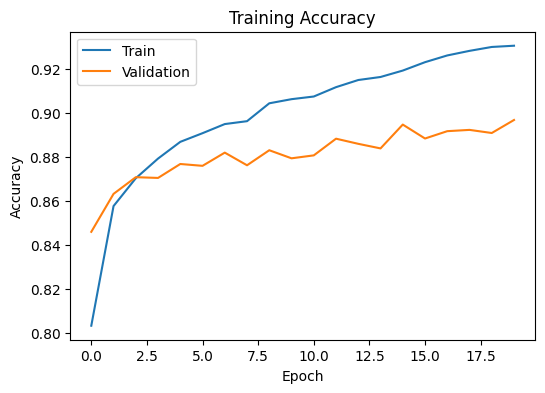

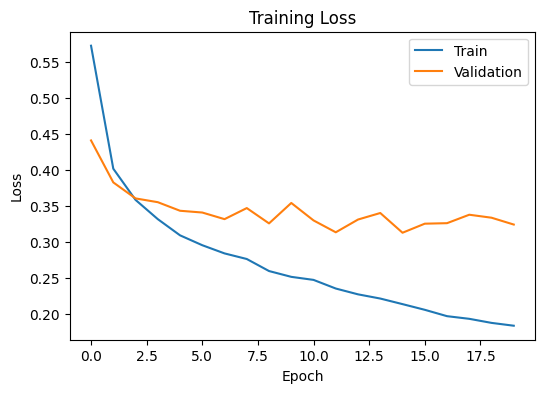

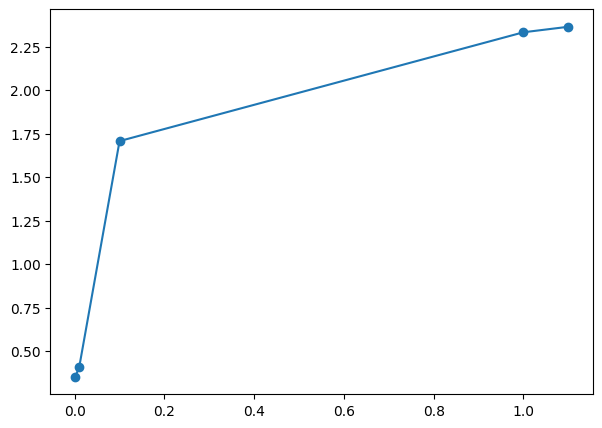

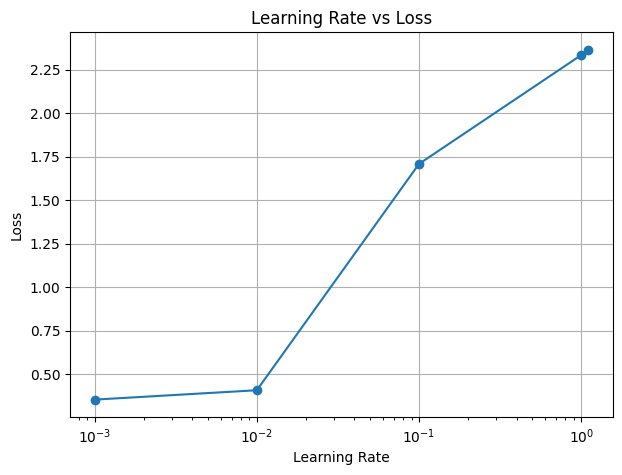

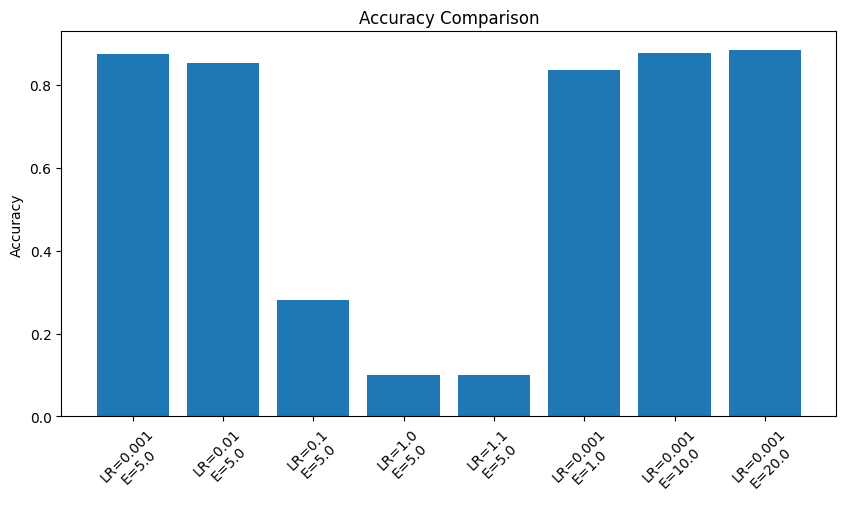

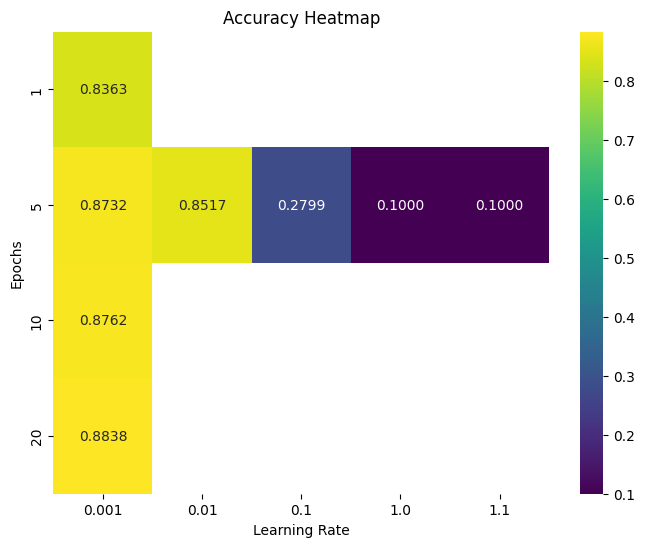

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8907 - loss: 0.3429

Final Test Accuracy : 0.8907
Final Test Loss     : 0.3429


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import pandas as pd


# MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0


# ---------------------------------------------------------
# Model
# ---------------------------------------------------------

def create_model(lr):

    model = Sequential([
        Dense(128, activation='relu', input_shape=(784,)),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# ---------------------------------------------------------
# USER INPUT
# ---------------------------------------------------------

num_lr = int(input("Enter number of learning rates: "))

learning_rates = []

for i in range(num_lr):
    lr = float(input(f"Enter Learning Rate {i+1}: "))
    learning_rates.append(lr)

print()

num_epochs = int(input("Enter number of epoch values: "))

epochs_list = []

for i in range(num_epochs):
    ep = int(input(f"Enter Epoch Value {i+1}: "))
    epochs_list.append(ep)


print("\nTraining Started...\n")


# ---------------------------------------------------------
# Effect of Learning Rate
# ---------------------------------------------------------

lr_results = []

for lr in learning_rates:

    model = create_model(lr)

    model.fit(
        x_train,
        y_train,
        epochs=5,
        batch_size=128,
        verbose=0
    )

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    lr_results.append([lr, 5, loss, acc])


lr_df = pd.DataFrame(
    lr_results,
    columns=["Learning Rate", "Epochs", "Loss", "Accuracy"]
)


print("Learning Rate Results")
print(lr_df)
print()


# ---------------------------------------------------------
# Effect of Epochs
# ---------------------------------------------------------

epoch_results = []

for ep in epochs_list:

    model = create_model(0.001)

    model.fit(
        x_train,
        y_train,
        validation_split=0.2,
        epochs=ep,
        batch_size=128,
        verbose=0
    )

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    epoch_results.append([0.001, ep, loss, acc])


epoch_df = pd.DataFrame(
    epoch_results,
    columns=["Learning Rate", "Epochs", "Loss", "Accuracy"]
)


print("Epoch Results")
print(epoch_df)
print()


# ---------------------------------------------------------
# Final Comparison Table
# ---------------------------------------------------------

comparison_df = pd.concat(
    [lr_df, epoch_df],
    ignore_index=True
)

comparison_df["Accuracy"] = comparison_df["Accuracy"].round(4)
comparison_df["Loss"] = comparison_df["Loss"].round(4)


print("=" * 60)
print("FINAL COMPARISON TABLE")
print("=" * 60)
print(comparison_df)


print("\nBest Configuration\n")

best = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print(best)


# ---------------------------------------------------------
# Plot Learning Rate vs Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(6, 4))

plt.plot(
    lr_df["Learning Rate"],
    lr_df["Accuracy"],
    marker='o'
)

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Learning Rate vs Accuracy")
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Plot Epoch vs Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(6, 4))

plt.plot(
    epoch_df["Epochs"],
    epoch_df["Accuracy"],
    marker='o'
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Epochs vs Accuracy")
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Train Final Model
# ---------------------------------------------------------

best_epoch = max(epochs_list)

model = create_model(0.001)

history = model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=best_epoch,
    batch_size=128,
    verbose=1
)


# ---------------------------------------------------------
# Training Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(6, 4))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.legend(["Train", "Validation"])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")

plt.show()


# ---------------------------------------------------------
# Loss Graph
# ---------------------------------------------------------

plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.legend(["Train", "Validation"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()


# ---------------------------------------------------------
# Learning Rate vs Loss
# ---------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    lr_df["Learning Rate"],
    lr_df["Loss"],
    marker='o'
)

plt.figure(figsize=(7, 5))

plt.plot(
    lr_df["Learning Rate"],
    lr_df["Loss"],
    marker='o'
)

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Loss")
plt.title("Learning Rate vs Loss")
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Accuracy Comparison
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

labels = []

for i in range(len(comparison_df)):
    labels.append(
        f"LR={comparison_df.iloc[i]['Learning Rate']}\n"
        f"E={comparison_df.iloc[i]['Epochs']}"
    )

plt.bar(
    labels,
    comparison_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.xticks(rotation=45)

plt.show()


# ---------------------------------------------------------
# Accuracy Heatmap
# ---------------------------------------------------------

import seaborn as sns

heatmap_data = comparison_df.pivot_table(
    values="Accuracy",
    index="Epochs",
    columns="Learning Rate"
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="viridis",
    fmt=".4f"
)

plt.title("Accuracy Heatmap")

plt.show()


# ---------------------------------------------------------
# Final Test Accuracy
# ---------------------------------------------------------

loss, acc = model.evaluate(x_test, y_test)

print("\nFinal Test Accuracy :", round(acc, 4))
print("Final Test Loss     :", round(loss, 4))